# 14. 의사라벨 활용 — 재학습, 현장 규칙, 검사 등급
13의 의사라벨(같은 모델·같은 절차로 Stellantis N.V.와 KAMP 모두 생성)을 세 가지로 쓴다. 모든 절차는 Stellantis N.V.에 똑같이 적용해 숨긴 정답으로 확인한다.
1. **재학습(self-training):** 소프트 의사라벨을 정답으로 CatBoost를 학습한다(날짜 하나 빼고). 검사 예산 성능을 PVC와 대응 비교한다.
   주의: 학습 날짜의 의사라벨은 평가 날짜의 개수도 써서 학습한 PVC에서 나왔다(개수 정보만 약하게 섞임, 개별 정답은 아님). 완전한 중첩 검증은 아니다.
2. **현장 규칙:** 얕은 결정나무(깊이 2)로 소프트 의사라벨을 설명한다. Stellantis N.V.에서는 규칙 구간별 실제 불량률을 함께 본다.
3. **검사 등급:** A = 날짜별 상위 c_d, B = 상위 5·c_d 중 A 제외, C = 나머지. Stellantis N.V.에서 등급별 실제 적중률을 잰다.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from catboost import CatBoostClassifier
from sklearn.tree import DecisionTreeRegressor, export_text
import br
from br import spec as S, plot as P
from wl.metrics import inclusion_prob
from wl import data as wldata
warnings.filterwarnings("ignore"); P.setup(); pd.set_option("display.width", 220)
DATA = {"polito": S.load_polito(), "kamp": S.load_kamp()}
sc = pd.read_pickle(br.RES / "same_model_scores.pkl")
def mean_col(ds, col):
    g = sc[(sc.data == ds) & (sc.model == "PVC MLP")]
    return np.mean([gg.sort_values("row")[col].values for _, gg in g.groupby("seed")], 0)

# 13과 같은 절차로 Stellantis N.V. 소프트 의사라벨을 다시 만든다(KAMP는 13의 CSV)
from scipy.special import expit, logit
from br.weak import shift_to
X, pday, pcnt, py, _ = DATA["polito"]
s_p, p_p = mean_col("polito", "score"), mean_col("polito", "prob")
soft_p = np.zeros(len(py))
for d, c in pcnt.items():
    m = pday == d; z = logit(np.clip(p_p[m], 1e-6, 1 - 1e-6)); soft_p[m] = expit(z + shift_to(z, c))
kp = pd.read_csv(br.RES / "kamp_pseudo_labels.csv")
Xk, kday, kcnt, _, kblk = DATA["kamp"]

## 1. 의사라벨 재학습 — CatBoost(소프트 라벨 가중), 날짜 하나 빼고 학습

In [2]:
def soft_fit_predict(Xv, soft, tr, te, seed):
    Xtr = np.r_[Xv[tr], Xv[tr]]; ytr = np.r_[np.ones(tr.sum()), np.zeros(tr.sum())]
    w = np.r_[soft[tr], 1 - soft[tr]]
    m = CatBoostClassifier(iterations=300, depth=4, learning_rate=0.05, random_seed=seed, verbose=0, thread_count=8, allow_writing_files=False)
    return m.fit(Xtr, ytr, sample_weight=w).predict_proba(Xv[te])[:, 1]

def self_train(Xdf, day, soft, usable, seeds=range(3)):
    Xv = Xdf.values.astype(float); Xv = np.where(np.isnan(Xv), np.nanmedian(Xv, 0), Xv)
    out = np.full(len(day), np.nan)
    days = np.unique(day[usable])
    preds = []
    for s in seeds:
        o = np.full(len(day), np.nan)
        for d in days:
            te = day == d; tr = usable & ~te
            o[te] = soft_fit_predict(Xv, soft, tr, te, s * 100 + hash(d) % 97)
        preds.append(o)
    return np.mean(preds, 0)

st_p = self_train(X, pday, soft_p, np.ones(len(py), bool))
body = wldata.load_polito().body.values
rng = np.random.default_rng(5); ub = np.unique(body)
Wb = np.stack([np.bincount(d_, minlength=len(ub)) for d_ in rng.integers(0, len(ub), (5000, len(ub)))])[:, np.searchsorted(ub, body)]
ud, gi = np.unique(pday, return_inverse=True); n = np.bincount(gi); pos = np.bincount(gi, weights=py)
rows = []
for b in (.05, .1, .2, .3):
    k = np.ceil(b * n - 1e-9)
    pa, pb = inclusion_prob(s_p, k, gi), inclusion_prob(st_p, k, gi)
    d_ = (Wb @ ((pb - pa) * py)) / (Wb @ py)
    rows.append({"예산": f"{int(b*100)}%", "무작위": round((k / n * pos).sum() / py.sum(), 3), "PVC(현재)": round((pa * py).sum() / py.sum(), 3),
                 "의사라벨 재학습": round((pb * py).sum() / py.sum(), 3),
                 "재학습−PVC [95%]": f"{d_.mean():+.3f} [{np.quantile(d_,.025):+.3f}, {np.quantile(d_,.975):+.3f}]"})
st_tab = pd.DataFrame(rows); st_tab.to_csv(br.RES / "pseudo_selftrain_polito.csv", index=False, encoding="utf-8-sig"); st_tab

,예산,무작위,PVC(현재),의사라벨 재학습,재학습−PVC [95%]
0,5%,0.062,0.101,0.114,"+0.012 [-0.031, +0.055]"
1,10%,0.108,0.278,0.278,"+0.002 [-0.069, +0.088]"
2,20%,0.202,0.468,0.405,"-0.063 [-0.123, +0.000]"
3,30%,0.309,0.658,0.494,"-0.168 [-0.261, -0.090]"


## 2. 현장 규칙 — 깊이 2 결정나무로 소프트 의사라벨 설명
KAMP는 원래 단위(kA, V, ms, bar)로 규칙을 쓴다. Stellantis N.V.는 정규화 단위라 규칙 자체는 옮길 수 없고, **같은 절차로 만든 규칙 구간이 실제로 불량이 많은지**만 확인한다.

In [3]:
RAW4 = ["cur", "vol", "time", "force"]
def rule_table(Xdf, soft, usable, y=None, min_leaf=0.05):
    Xv = Xdf[RAW4].copy(); Xv = Xv.fillna(Xv.median())
    t = DecisionTreeRegressor(max_depth=2, min_samples_leaf=int(min_leaf * usable.sum()), random_state=0).fit(Xv[usable], soft[usable])
    leaf = t.apply(Xv)
    g = pd.DataFrame({"leaf": leaf[usable], "soft": soft[usable]})
    if y is not None: g["y"] = y[usable]
    tab = g.groupby("leaf").agg(타점수=("soft", "size"), 의사불량률=("soft", "mean"), **({"실제불량률": ("y", "mean")} if y is not None else {}))
    tab["비중"] = tab.타점수 / tab.타점수.sum()
    return t, tab.sort_values("의사불량률", ascending=False)

t_p, tab_p = rule_table(X, soft_p, np.ones(len(py), bool), py)
print("[Stellantis N.V.] 의사라벨로 만든 규칙 구간의 실제 불량률 (전체 불량률 %.3f)" % py.mean())
display(tab_p.round(4))
kp_soft = kp["의사불량확률(소프트)"].values
use_k = (~kblk) & (kp["라벨근거"].values == "실제 일별 개수")
Xk_raw = pd.DataFrame({"cur": kp["weld current(kA)"], "vol": kp["weld Voltage(v)"], "time": kp["weld time(ms)"], "force": kp["weld force(bar)"]})
t_k, tab_k = rule_table(Xk_raw, kp_soft, use_k)
print("[KAMP] 규칙 (단위: kA, V, ms, bar)")
print(export_text(t_k, feature_names=["전류(kA)", "전압(V)", "통전시간(ms)", "가압력(bar)"], decimals=3))
tab_k["의사불량률/평균"] = tab_k.의사불량률 / kp_soft[use_k].mean()
tab_k.round(4)

[Stellantis N.V.] 의사라벨로 만든 규칙 구간의 실제 불량률 (전체 불량률 0.040)


,타점수,의사불량률,실제불량률,비중
leaf,,,,
6,237,0.2243,0.1055,0.1199
3,329,0.0402,0.0608,0.1665
5,356,0.0346,0.0169,0.1802
2,1054,0.0003,0.0266,0.5334


[KAMP] 규칙 (단위: kA, V, ms, bar)
|--- 가압력(bar) <= 2.385
|   |--- 전류(kA) <= 14.565
|   |   |--- value: [0.019]
|   |--- 전류(kA) >  14.565
|   |   |--- value: [0.002]
|--- 가압력(bar) >  2.385
|   |--- value: [0.022]



,타점수,의사불량률,비중,의사불량률/평균
leaf,,,,
4,555,0.0218,0.0589,5.2584
2,670,0.0185,0.0711,4.4715
3,8193,0.0018,0.8699,0.4276


## 3. 검사 등급 — Stellantis N.V.에서 등급별 실제 적중, KAMP에서 등급별 수량

In [4]:
def tiers(score, day, cnt, rankable):
    tier = np.full(len(day), "C", dtype=object)
    for d, c in cnt.items():
        m = (day == d) & rankable
        if np.isnan(c) or not m.any(): continue
        ix = np.flatnonzero(m); order = ix[np.argsort(-score[m], kind="stable")]
        tier[order[:int(5 * c)]] = "B"; tier[order[:int(c)]] = "A"
    tier[~rankable] = "-"
    return tier
tp = tiers(s_p, pday, pcnt.astype(float), np.ones(len(py), bool))
pt = pd.DataFrame({"tier": tp, "y": py}).groupby("tier").agg(타점=("y", "size"), 실제불량=("y", "sum"))
pt["적중률"] = pt.실제불량 / pt.타점; pt["불량 중 비중"] = pt.실제불량 / py.sum(); pt["대 평균 배수"] = pt.적중률 / py.mean()
print("[Stellantis N.V.] 등급별 실제 적중"); display(pt.round(3))
cnt_use = kcnt.copy(); cnt_use["2020-03-27"] = kp.loc[kp.date == "2020-03-27", "의사불량(하드)"].sum()
tk = tiers(kp["위험점수"].values, kday, cnt_use, ~kblk)
kt = pd.DataFrame({"date": kday, "tier": tk}).pivot_table(index="date", columns="tier", aggfunc="size", fill_value=0)
kt["A+B 비율"] = (kt.A + kt.B) / kt.sum(axis=1)
print("[KAMP] 날짜별 등급 수량 (- = 복사 블록, 품질확인)"); display(kt)
kp["검사등급"] = tk
kp.to_csv(br.RES / "kamp_pseudo_labels.csv", index=False, encoding="utf-8-sig")

[Stellantis N.V.] 등급별 실제 적중


,타점,실제불량,적중률,불량 중 비중,대 평균 배수
tier,,,,,
A,79,16,0.203,0.203,5.066
B,296,29,0.098,0.367,2.451
C,1601,34,0.021,0.430,0.531


[KAMP] 날짜별 등급 수량 (- = 복사 블록, 품질확인)


tier,-,A,B,C,A+B 비율
date,,,,,
2020-03-24,0,4,16,1180,0.016667
2020-03-25,291,8,32,1021,0.029586
2020-03-26,0,7,28,965,0.035000
2020-03-27,291,6,24,1327,0.018204
2020-03-30,0,4,16,1450,0.013605
2020-03-31,291,5,20,1484,0.013889
2020-04-02,0,4,16,1980,0.010000
2020-04-03,291,4,16,489,0.025000
2020-04-07,0,3,12,654,0.022422


## 4. 그림 — 의사라벨 활용 요약

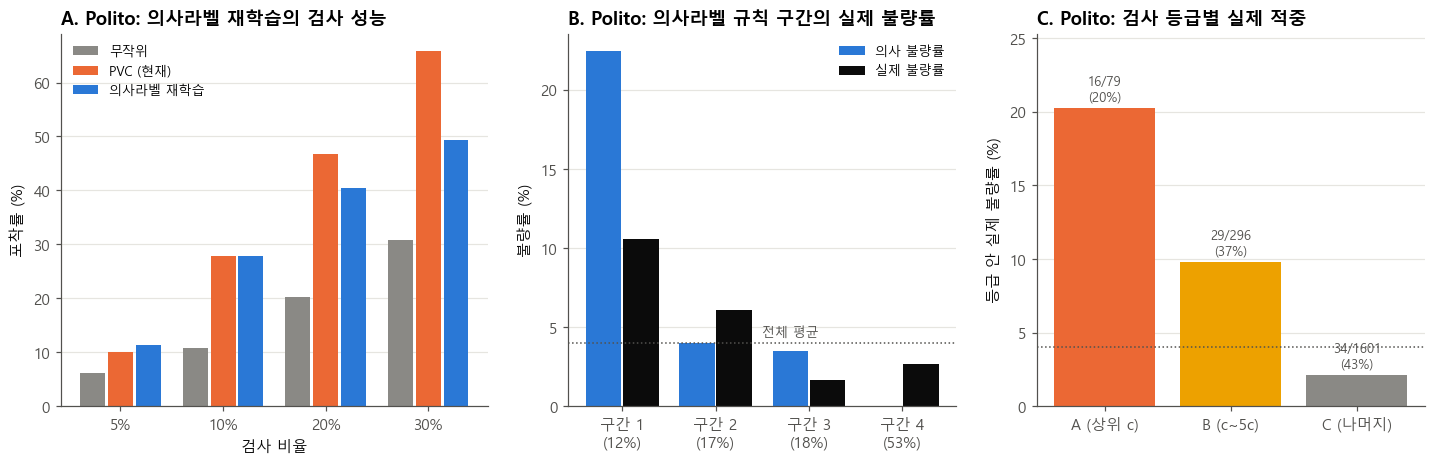

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1.1, 1, 1]})
ax = axes[0]
bb = [5, 10, 20, 30]; x = np.arange(len(bb)); w = .27
ax.bar(x - w, st_tab["무작위"] * 100, w * .9, color=P.GRAY, label="무작위")
ax.bar(x, st_tab["PVC(현재)"] * 100, w * .9, color=P.PAL[1], label="PVC (현재)")
ax.bar(x + w, st_tab["의사라벨 재학습"] * 100, w * .9, color=P.PAL[0], label="의사라벨 재학습")
ax.set_xticks(x); ax.set_xticklabels([f"{b}%" for b in bb]); ax.set_xlabel("검사 비율"); ax.set_ylabel("포착률 (%)")
ax.set_title("A. Stellantis N.V.: 의사라벨 재학습의 검사 성능", loc="left", fontweight="bold"); ax.legend(fontsize=8.5); ax.grid(axis="x", visible=False)
ax = axes[1]
tt = tab_p.reset_index(drop=True)
ax.bar(np.arange(len(tt)) - .2, tt.의사불량률 * 100, .38, color=P.PAL[0], label="의사 불량률")
ax.bar(np.arange(len(tt)) + .2, tt.실제불량률 * 100, .38, color=P.INK, label="실제 불량률")
ax.axhline(py.mean() * 100, color=P.INK2, ls=":", lw=1); ax.text(1.5, py.mean() * 100 + .4, "전체 평균", color=P.INK2, fontsize=8.5)
ax.set_xticks(range(len(tt))); ax.set_xticklabels([f"구간 {i+1}\n({v:.0%})" for i, v in enumerate(tt.비중)]); ax.set_ylabel("불량률 (%)")
ax.set_title("B. Stellantis N.V.: 의사라벨 규칙 구간의 실제 불량률", loc="left", fontweight="bold"); ax.legend(fontsize=8.5); ax.grid(axis="x", visible=False)
ax = axes[2]
ax.bar(pt.index, pt.적중률 * 100, color=[P.PAL[1], P.PAL[3], P.GRAY])
for i, (tr_, r) in enumerate(pt.iterrows()):
    ax.text(i, r.적중률 * 100 + .5, f"{int(r.실제불량)}/{int(r.타점)}\n({r['불량 중 비중']:.0%})", ha="center", fontsize=8.5, color=P.INK2)
ax.axhline(py.mean() * 100, color=P.INK2, ls=":", lw=1)
ax.set_ylim(0, pt.적중률.max() * 125); ax.set_ylabel("등급 안 실제 불량률 (%)"); ax.set_title("C. Stellantis N.V.: 검사 등급별 실제 적중", loc="left", fontweight="bold"); ax.grid(axis="x", visible=False)
ax.set_xticklabels(["A (상위 c)", "B (c~5c)", "C (나머지)"])
P.save(fig, "12_pseudo_label_use"); plt.show()